# A2 sign check: does the loaded zone of a ball bearing face the load on the shaft?

**Case:** `validation/bearings/iso16281_ball_contact`
**Type:** equilibrium check of the shaft -> bearing path (open review item A2 on `phi_Fr`)

A plain shaft on two 6210-like ball bearings carries one radial load at mid-span
(`construction.build_shaft_system`), in two directions: along $-Z$, and at `theta_deg` = 300
(AxisForge `RadialLoad`, from $+Y$ toward $+Z$), where both $F_y$ and $F_z$ are non-zero, so the
$Y$ sign and the sense of rotation of D-0010 are tested too. The rigid-support FEM gives the force
at each bearing node; the ISO/TS 16281 ball solver then distributes it over the balls, as a study
does (`psi = 0` prescribed, `Fa = 0`, clearance 0).

Physics. The shaft pushes the inner ring along the load; the inner ring is held by the balls. A
ball at the global angle $\varphi_j$ (D-0010: from $+Z$ toward $+Y$) pushes the inner ring toward
the bearing axis with the radial component $Q_j \cos\alpha_j$. With $F_r$ = force of the support
ON THE SHAFT (what the FEM stores, so the shaft pushes the inner ring with $-F_r$), equilibrium of
the inner ring in the radial plane is

$$ \mathbf{r} = \sum_j Q_j \cos\alpha_j \,(\cos\varphi_j, \sin\varphi_j) + (F_{r,xz}, F_{r,xy}) = \mathbf{0}, $$

and the most loaded ball sits under the load, at the angle of the load direction measured from
$+Z$ toward $+Y$: $\varphi_\mathrm{exp} = \operatorname{atan2}(F_{y,\mathrm{load}}, F_{z,\mathrm{load}}) \bmod 2\pi$,
that is 180 deg for $-Z$ and 150 deg for `theta_deg` = 300.

Criterion (fixed before running; plan section 4): **PASS** if $|\mathbf{r}| \le 10^{-3} |F_r|$ and
$\arg\max_j Q_j$ at $\varphi_\mathrm{exp}$ within half the ball pitch angle $\pi/Z$. **FAIL
signature**: $|\mathbf{r}| \approx 2 |F_r|$ and $\arg\max_j Q_j$ at $\varphi_\mathrm{exp} + \pi$. The
vector residual decides. Predicted from reading the code: FAIL (see the README). Nothing is raised
on FAIL: the result is evidence for José's A2 ruling, AxisForge is not changed.

In [1]:
import math
import pathlib

import matplotlib.pyplot as plt
import numpy as np

import axisforge.mesh as af_m
from axisforge.outputs._format import format_table, write_records_csv
# importing contact_solver registers the ball and roller solvers with the dispatcher
from axisforge.solvers.machine_elements.bearings.load_distribution.iso_16281 import contact_solver  # noqa: F401
from axisforge.solvers.machine_elements.bearings.load_distribution.iso_16281.dispatch import resolve_solver_cls
from axisforge.solvers.machine_elements.shaft.fem_solvers.global_solver.rigid_support import RigidSupportFEMSolver

from validation._support.figures import bearing_plots
from validation._support.style import use_style

import construction as cd

use_style()                                       # house paper style (style/README.md)
# the case folder: the script's own folder, or the working directory when run as a notebook
HERE = pathlib.Path(__file__).resolve().parent if "__file__" in globals() else pathlib.Path.cwd()
RESULTS = HERE / "results"                                          # git-ignored (D-0020)
RESULTS.mkdir(exist_ok=True)

RESIDUAL_TOL = 1e-3          # |r| / |Fr|: the solver converges far below this; a sign error gives ~2

## 1. Shaft FEM, then the ISO/TS 16281 ball solver per bearing

The force taken as $F_r$ is the FEM node force `BearingNodeData.Fr_xz`, `.Fr_xy` (AxisForge
`results/fem_results/shaft_results.py:26-27, 50-53`): `K d` at the bearing node, the force of the
support ON THE SHAFT, positive along $+Z$ / $+Y$. No load reaches the bearing nodes here, so it
equals the support reaction `ShaftResults.R_xz`, `R_xy` (`K d - f_ext`); both are recorded. It is
also the force the ball solver reads (`contact_solver.py:191-194`). The solver is run without
post-processing: the check needs the load distribution only, not stiffness or life.

AxisForge's own `BearingResult.equilibrium_error` (`load_distribution_results.py:429-432`)
compares magnitudes only, so it cannot see a 180 deg error; that is why the vector residual is
formed here.

In [2]:
beam = af_m.BeamModelSettings("timoshenko", "cowper", "single_point")
records, element_rows = [], []
for theta_deg in cd.SIGN_CHECK["load_theta_deg"]:
    shaft_system = cd.build_shaft_system(theta_deg)
    load = shaft_system.radial_loads[0]
    # direction of the load on the shaft in the D-0010 bearing angle (from +Z toward +Y)
    phi_expected = math.atan2(load.Fy, load.Fz) % (2.0 * math.pi)
    shaft_results = RigidSupportFEMSolver(beam).solve(shaft_system)
    reaction = dict(zip(shaft_results.bearing_positions, zip(shaft_results.R_xz, shaft_results.R_xy)))
    for node in shaft_results.bearing_nodes:
        bearing = next(b for b in shaft_system.bearings if b.label == node.label)
        solver = resolve_solver_cls(bearing, label=node.label)(psi_input=True, postprocess=False)
        result = solver.solve(shaft_system, {node.label: bearing}, shaft_results,
                              psi_override={node.label: 0.0})[node.label].load_distribution
        row = result.rows[0]
        Q, alpha = np.asarray(row.Q_j), np.asarray(row.alpha_j)
        phi_g = result.phi_j_global(0)          # global angle in [0, 2 pi): 0 on +Z, toward +Y (D-0010)
        # radial component of each ball force on the inner ring, toward the axis, summed as a vector
        radial = Q * np.cos(alpha)
        sum_xz, sum_xy = float(np.sum(radial * np.cos(phi_g))), float(np.sum(radial * np.sin(phi_g)))
        Fr = math.hypot(node.Fr_xz, node.Fr_xy)
        r_xz, r_xy = sum_xz + node.Fr_xz, sum_xy + node.Fr_xy
        ratio = math.hypot(r_xz, r_xy) / Fr
        j_max = int(np.argmax(Q))
        # angular distance of the most loaded ball from the expected angle, wrapped to [0, pi]
        off = abs((phi_g[j_max] - phi_expected + math.pi) % (2.0 * math.pi) - math.pi)
        at_expected = off <= math.pi / row.Z    # half the ball pitch angle 2 pi / Z
        R_xz, R_xy = reaction[node.position]
        records.append({
            "theta_deg": theta_deg, "label": node.label, "solver_ok": bool(result.ok),
            "Fr_xz_N": node.Fr_xz, "Fr_xy_N": node.Fr_xy, "R_xz_N": R_xz, "R_xy_N": R_xy, "Fr_N": Fr,
            "phi_Fr_rad": result.phi_Fr, "sum_xz_N": sum_xz, "sum_xy_N": sum_xy,
            "residual_xz_N": r_xz, "residual_xy_N": r_xy, "residual_ratio": ratio,
            "j_Qmax": j_max, "Q_max_N": float(Q[j_max]), "phi_g_Qmax_rad": float(phi_g[j_max]),
            "phi_expected_rad": phi_expected, "Qmax_at_expected": at_expected,
            "verdict": "PASS" if ratio <= RESIDUAL_TOL and at_expected else "FAIL",
        })
        element_rows += [{"theta_deg": theta_deg, "label": node.label, "j": j, "phi_g_rad": float(phi_g[j]),
                          "Q_N": float(Q[j]), "alpha_rad": float(alpha[j])} for j in range(row.Z)]

write_records_csv(RESULTS / "sign_check.csv", records)

## 2. Ball loads against their global angle

Where the loaded zone is; it should be centred on the expected angle (180 deg for $-Z$, 150 deg
for `theta_deg` = 300), the side the load pushes the inner ring.

In [3]:
DEG = math.degrees(1.0)
print(format_table([("theta_deg", "theta [deg]", ".0f"), ("label", "bearing", ""), ("j", "j", "d"),
                    ("phi_g_rad", "phi_g [deg]", ".1f", DEG), ("Q_N", "Q [N]", ".1f"),
                    ("alpha_rad", "alpha [deg]", ".3f", DEG)],
                   [e for e in element_rows if e["Q_N"] > 0.0]))

theta [deg]  bearing  j  phi_g [deg]   Q [N]  alpha [deg]
-----------  -------  -  -----------  ------  -----------
        270   6210_A  0          0.0  1607.9        0.000
        270   6210_A  1         40.0  1078.1        0.000
        270   6210_A  2         80.0   116.4        0.000
        270   6210_A  7        280.0   116.4        0.000
        270   6210_A  8        320.0  1078.1        0.000
        270   6210_B  0          0.0  1607.9        0.000
        270   6210_B  1         40.0  1078.1        0.000
        270   6210_B  2         80.0   116.4        0.000
        270   6210_B  7        280.0   116.4        0.000
        270   6210_B  8        320.0  1078.1        0.000
        300   6210_A  0        330.0  1607.9        0.000
        300   6210_A  1         10.0  1078.1        0.000
        300   6210_A  2         50.0   116.4        0.000
        300   6210_A  7        250.0   116.4        0.000
        300   6210_A  8        290.0  1078.1        0.000
        300   

The same ball loads as a figure, one panel per load direction with both bearings: the load
direction used by the solver $\varphi_{F_r}$ (dashed) against the expected $\varphi_\mathrm{exp}$
(dotted), and the residual $\vert r\vert/\vert F_r\vert$ of each bearing in the panel label.

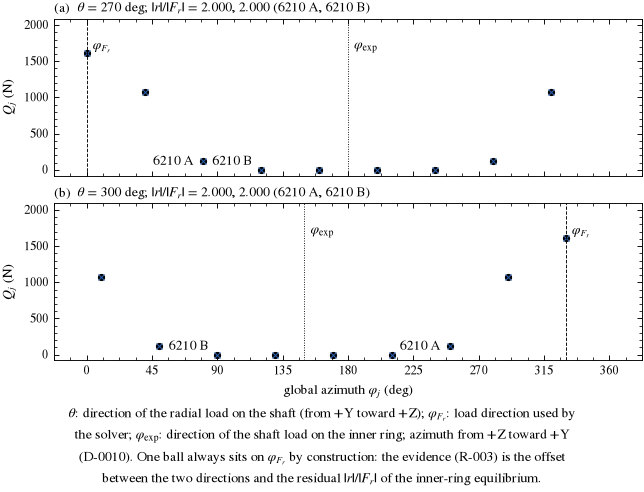

In [4]:
thetas = list(dict.fromkeys(r["theta_deg"] for r in records))
by_theta = {t: [r for r in records if r["theta_deg"] == t] for t in thetas}
for t, recs in by_theta.items():     # one line per direction in the panel: both bearings must share it
    assert all(abs(r["phi_Fr_rad"] - recs[0]["phi_Fr_rad"]) < 1e-9 for r in recs), t
    assert all(abs(r["phi_expected_rad"] - recs[0]["phi_expected_rad"]) < 1e-9 for r in recs), t
elements = {(t, r["label"]): [e for e in element_rows if (e["theta_deg"], e["label"]) == (t, r["label"])]
            for t, recs in by_theta.items() for r in recs}
fig = bearing_plots.sign_check(
    [[[e["phi_g_rad"] for e in elements[t, r["label"]]] for r in recs] for t, recs in by_theta.items()],
    [[[e["Q_N"] for e in elements[t, r["label"]]] for r in recs] for t, recs in by_theta.items()],
    phi_Fr_rad=[recs[0]["phi_Fr_rad"] for recs in by_theta.values()],
    phi_expected_rad=[recs[0]["phi_expected_rad"] for recs in by_theta.values()],
    series=[r["label"] for r in by_theta[thetas[0]]],
    labels=[rf"$\theta$ = {t:.0f} deg; $\vert r\vert/\vert F_r\vert$ = " + ", ".join(f"{r['residual_ratio']:.3f}" for r in recs)
            + " (" + ", ".join(r["label"] for r in recs) + ")" for t, recs in by_theta.items()])
fig.savefig(RESULTS / "02_sign_check.png")
plt.close(fig)                                    # shown once, by the line below
fig

## 3. Equilibrium of the inner ring and the verdict

In [5]:
print(format_table([
    ("theta_deg", "theta [deg]", ".0f"), ("label", "bearing", ""), ("solver_ok", "solved", ""),
    ("Fr_xz_N", "Fr_xz [N]", ".3f"), ("Fr_xy_N", "Fr_xy [N]", ".3f"),
    ("R_xz_N", "R_xz [N]", ".3f"), ("R_xy_N", "R_xy [N]", ".3f"),
    ("phi_Fr_rad", "phi_Fr [deg]", ".3f", DEG), ("sum_xz_N", "sum Q cos(a) cos(phi) [N]", ".3f"),
    ("sum_xy_N", "sum Q cos(a) sin(phi) [N]", ".3f"), ("residual_xz_N", "r_xz [N]", ".3f"),
    ("residual_xy_N", "r_xy [N]", ".3f"), ("residual_ratio", "|r|/|Fr|", ".6f"),
    ("Q_max_N", "Q_max [N]", ".1f"), ("phi_g_Qmax_rad", "phi_g(Q_max) [deg]", ".1f", DEG),
    ("phi_expected_rad", "expected [deg]", ".1f", DEG), ("verdict", "A2", ""),
], records))
for rec in records:
    print(f"A2 sign check: {rec['verdict']}  theta {rec['theta_deg']:.0f} deg  {rec['label']}  "
          f"|residual|/|Fr| = {rec['residual_ratio']:.6f}, Q_max at phi_g = {rec['phi_g_Qmax_rad'] * DEG:.1f} deg "
          f"(expected {rec['phi_expected_rad'] * DEG:.1f} deg)")
print(f"\nwritten: {(RESULTS / 'sign_check.csv').relative_to(HERE)}")

theta [deg]  bearing  solved  Fr_xz [N]  Fr_xy [N]  R_xz [N]   R_xy [N]  phi_Fr [deg]  sum Q cos(a) cos(phi) [N]  sum Q cos(a) sin(phi) [N]  r_xz [N]   r_xy [N]  |r|/|Fr|  Q_max [N]  phi_g(Q_max) [deg]  expected [deg]    A2
-----------  -------  ------  ---------  ---------  --------  ---------  ------------  -------------------------  -------------------------  --------  ---------  --------  ---------  ------------------  --------------  ----
        270   6210_A     yes   3300.000      0.000  3300.000      0.000         0.000                   3300.000                      0.000  6600.000      0.000  2.000000     1607.9                 0.0           180.0  FAIL
        270   6210_B     yes   3300.000      0.000  3300.000      0.000         0.000                   3300.000                      0.000  6600.000      0.000  2.000000     1607.9                 0.0           180.0  FAIL
        300   6210_A     yes   2857.884  -1650.000  2857.884  -1650.000       -30.000                   